In [1]:
## 1. Build the graph. Construct a directed graph whose nodes are metabolites and which has 
## an edge from every substrate to every product of each reaction. Reversible reactions con-
## tribute edges in both directions. Exclude the biomass pseudo-reaction (Biomass Ecoli core)
## and the exchange reactions (identifiers beginning EX ): the first is not a chemical reaction
## but a bookkeeping device that lists some twenty precursors as substrates and several of
## them as products, and including it creates edges between metabolites that no enzyme con-
## nects. State how many edges it would have added. Report the number of nodes and edges
## and the density. Compute the degree and the betweenness centrality of every metabolite,
## and list the ten highest by each measure. Say which of these you would describe as cur-
## rency metabolites: molecules such as ATP, water, protons and NADH that take part in a
## large fraction of all reactions without being the object of any of them.

In [2]:
pip install cobra networkx matplotlib pandas

   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 1.2/1.2 MB 5.5 MB/s  0:00:00
   ---------------------------------------- 0.0/5.8 MB ? eta -:--:--
   ------- -------------------------------- 1.0/5.8 MB 6.3 MB/s eta 0:00:01
   ---------------- ----------------------- 2.4/5.8 MB 6.0 MB/s eta 0:00:01
   ------------------------- -------------- 3.7/5.8 MB 5.9 MB/s eta 0:00:01
   -------------------------------- ------- 4.7/5.8 MB 5.9 MB/s eta 0:00:01
   ---------------------------------------- 5.8/5.8 MB 5.7 MB/s  0:00:01
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ------------------- -------------------- 1.0/2.2 MB 6.1 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 5.7 MB/s  0:00:00
   ---------------------------------------- 0.0/581.5 kB ? eta -:--:--
   ---------------------------------------- 581.5/581.5 kB 5.3 MB/s  0:00:00
   ---------------------------------------- 0.


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import random, collections
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from cobra.io import load_model


Output()

72 metabolites, 95 reactions
Biomass reaction: Biomass_Ecoli_core
  raw edges it generates: 112
  NEW edges it would add to the graph: 78

Nodes: 72  Edges: 377  Density: 0.0737
Isolated nodes: []

Top 10 by degree


,degree,in,out,betweenness,n_reactions,frac_reactions
h_c,63,38,25,0.3728,34,0.4595
h2o_c,34,14,20,0.1685,17,0.2297
h_e,31,14,17,0.0747,16,0.2162
pi_c,27,17,10,0.0519,11,0.1486
pyr_c,23,11,12,0.0429,10,0.1351
nadh_c,23,11,12,0.0331,11,0.1486
adp_c,22,13,9,0.0590,11,0.1486
atp_c,20,8,12,0.0380,12,0.1622
nad_c,20,10,10,0.0297,11,0.1486
g3p_c,18,9,9,0.0916,6,0.0811


Top 10 by betweenness


,degree,in,out,betweenness,n_reactions,frac_reactions
h_c,63,38,25,0.3728,34,0.4595
h2o_c,34,14,20,0.1685,17,0.2297
g3p_c,18,9,9,0.0916,6,0.0811
h_e,31,14,17,0.0747,16,0.2162
f6p_c,17,9,8,0.0599,6,0.0811
adp_c,22,13,9,0.0590,11,0.1486
pi_c,27,17,10,0.0519,11,0.1486
co2_c,17,11,6,0.0447,9,0.1216
pyr_c,23,11,12,0.0429,10,0.1351
nadp_c,17,8,9,0.0389,8,0.1081


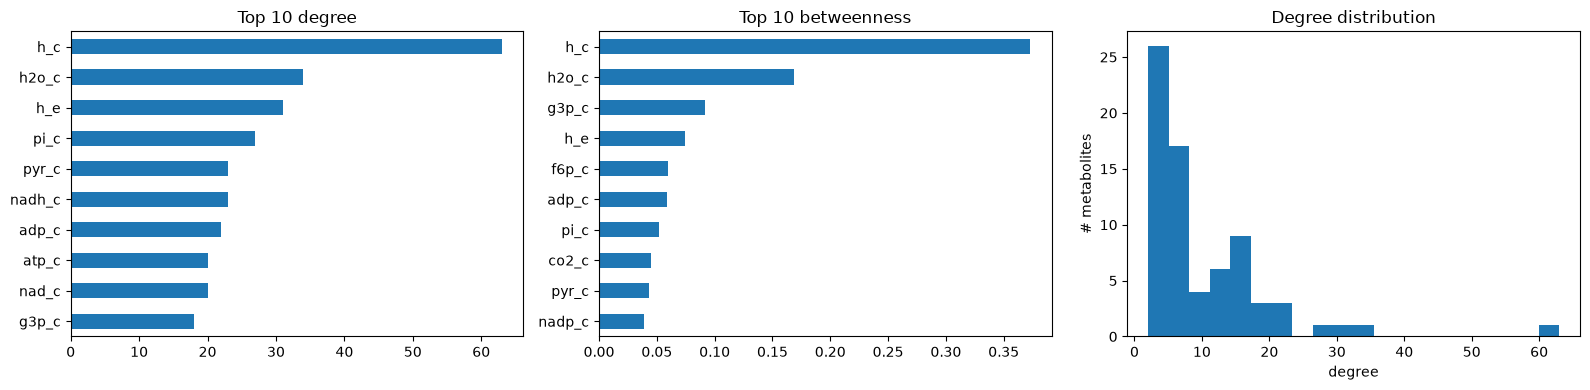

In [2]:
SEED = 42
random.seed(SEED); np.random.seed(SEED)  

try:
    model = load_model("e_coli_core")
except Exception:
    model = load_model("textbook")        
print(len(model.metabolites), "metabolites,", len(model.reactions), "reactions")

def is_biomass(r):  return r.id.lower().startswith("biomass")
def is_exchange(r): return r.id.startswith("EX_")

def reaction_edges(rxn):
    """Substrate -> product edges; reversed edges too if the reaction can run backwards."""
    subs  = [m.id for m, c in rxn.metabolites.items() if c < 0]
    prods = [m.id for m, c in rxn.metabolites.items() if c > 0]
    out = []
    if rxn.upper_bound > 0: out += [(s, p) for s in subs for p in prods]
    if rxn.lower_bound < 0: out += [(p, s) for s in subs for p in prods]
    return out

def build_graph(model, include_biomass=False):
    G = nx.DiGraph()
    G.add_nodes_from(m.id for m in model.metabolites)
    used = []
    for r in model.reactions:
        if is_exchange(r): continue
        if is_biomass(r) and not include_biomass: continue
        used.append(r)
        for u, v in reaction_edges(r):
            if u != v:                      # ignore self-loops
                G.add_edge(u, v)
    return G, used

G, used_rxns = build_graph(model)

# --- how many edges would the biomass reaction have added? ---
G_bio, _ = build_graph(model, include_biomass=True)
bio = [r for r in model.reactions if is_biomass(r)][0]
added = set(G_bio.edges) - set(G.edges)
print(f"Biomass reaction: {bio.id}")
print(f"  raw edges it generates: {len(set(reaction_edges(bio)))}")
print(f"  NEW edges it would add to the graph: {len(added)}")

# --- basic statistics ---
n_nodes, n_edges = G.number_of_nodes(), G.number_of_edges()
print(f"\nNodes: {n_nodes}  Edges: {n_edges}  Density: {nx.density(G):.4f}")
print("Isolated nodes:", list(nx.isolates(G)))

# --- centralities ---
deg, indeg, outdeg = dict(G.degree()), dict(G.in_degree()), dict(G.out_degree())  # deg = in + out
btw = nx.betweenness_centrality(G)                                               # exact, deterministic
n_rx = len(used_rxns)
part = {m.id: sum(1 for r in used_rxns if m in r.metabolites) for m in model.metabolites}

df = pd.DataFrame({"degree": deg, "in": indeg, "out": outdeg, "betweenness": btw,
                   "n_reactions": part})
df["frac_reactions"] = df["n_reactions"] / n_rx

print("\nTop 10 by degree")
top_deg = df.sort_values(["degree", "betweenness"], ascending=False).head(10)
display(top_deg.round(4))

print("Top 10 by betweenness")
top_btw = df.sort_values("betweenness", ascending=False).head(10)
display(top_btw.round(4))

# --- plots ---
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
top_deg["degree"][::-1].plot.barh(ax=ax[0], title="Top 10 degree")
top_btw["betweenness"][::-1].plot.barh(ax=ax[1], title="Top 10 betweenness")
ax[2].hist(list(deg.values()), bins=20); ax[2].set_title("Degree distribution")
ax[2].set_xlabel("degree"); ax[2].set_ylabel("# metabolites")
plt.tight_layout(); plt.show()

In [ ]:
## 2. Fewest reactions. Using breadth-first search, compute the shortest path in number of
## reactions for the pairs
## • g6p c → pyr c (glucose-6-phosphate to pyruvate),
## • g6p c → succ c (glucose-6-phosphate to succinate),
## • 3pg c → glu L c (3-phosphoglycerate to glutamate).
## The source is glucose-6-phosphate rather than glucose because the model contains no
## cytoplasmic glucose: glucose enters through the phosphotransferase reaction GLCpts,
## which consumes extracellular glucose and phosphoenolpyruvate and produces glucose-
## 6-phosphate and pyruvate in one step. Check this, and say what it implies for a path
## from glc D e to pyr c. Report the length and the full path for each pair. Compare the
## first with the glycolytic sequence from glucose-6-phosphate to pyruvate as given in any
## biochemistry textbook. Then remove the k highest-degree metabolites from the graph for
## k ∈ {0, 2, 5, 10, 15}, never removing the source or the target of a pair, and recompute all
## three paths at each k. Tabulate how the lengths and the paths themselves change, note
## the k at which a pair first becomes disconnected and which removed metabolite discon-
## nected it, and identify the value of k at which the first path coincides with glycolysis, if
## it ever does. State what this tells you about the paths found at k = 0, and about degree
## as a criterion for what to remove.

Cytoplasmic glucose in model: ['glc__D_e']
GLCpts: glc__D_e + pep_c --> g6p_c + pyr_c | bounds (0.0, 1000.0)
glc__D_e -> pyr_c: ['glc__D_e', 'pyr_c'] length 1

Glycolysis edges present in G: True | length 8

k = 0
  g6p_c -> pyr_c: length 2 (1 shortest path(s) exist)
    g6p_c -> h_c -> pyr_c
  g6p_c -> succ_c: length 3 (6 shortest path(s) exist)
    g6p_c -> f6p_c -> adp_c -> succ_c
  3pg_c -> glu__L_c: length 3 (3 shortest path(s) exist)
    3pg_c -> 2pg_c -> h2o_c -> glu__L_c


,pair,k,length,is_glycolysis,path
0,g6p_c->pyr_c,0,2.0,False,g6p_c -> h_c -> pyr_c
1,g6p_c->pyr_c,2,3.0,False,g6p_c -> 6pgl_c -> nadp_c -> pyr_c
2,g6p_c->pyr_c,5,3.0,False,g6p_c -> 6pgl_c -> nadp_c -> pyr_c
3,g6p_c->pyr_c,10,3.0,False,g6p_c -> 6pgl_c -> nadp_c -> pyr_c
4,g6p_c->pyr_c,15,NaN,False,DISCONNECTED
5,g6p_c->succ_c,0,3.0,None,g6p_c -> f6p_c -> adp_c -> succ_c
6,g6p_c->succ_c,2,3.0,None,g6p_c -> f6p_c -> adp_c -> succ_c
7,g6p_c->succ_c,5,3.0,None,g6p_c -> f6p_c -> adp_c -> succ_c
8,g6p_c->succ_c,10,3.0,None,g6p_c -> nadph_c -> icit_c -> succ_c
9,g6p_c->succ_c,15,3.0,None,g6p_c -> nadph_c -> icit_c -> succ_c


Removed sets per pair:
g6p_c -> pyr_c
  k=2: ['h_c', 'h2o_c']
  k=5: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c']
  k=10: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c', 'adp_c', 'atp_c', 'nad_c', 'g3p_c', 'co2_c']
  k=15: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c', 'adp_c', 'atp_c', 'nad_c', 'g3p_c', 'co2_c', 'coa_c', 'f6p_c', 'glu__L_c', 'mal__L_c', 'nadp_c']
g6p_c -> succ_c
  k=2: ['h_c', 'h2o_c']
  k=5: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c']
  k=10: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c', 'pyr_c', 'adp_c', 'atp_c', 'nad_c', 'g3p_c']
  k=15: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c', 'pyr_c', 'adp_c', 'atp_c', 'nad_c', 'g3p_c', 'co2_c', 'coa_c', 'f6p_c', 'glu__L_c', 'mal__L_c']
3pg_c -> glu__L_c
  k=2: ['h_c', 'h2o_c']
  k=5: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c']
  k=10: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c', 'pyr_c', 'adp_c', 'atp_c', 'nad_c', 'g3p_c']
  k=15: ['h_c', 'h2o_c', 'h_e', 'pi_c', 'nadh_c', 'pyr_c', 'adp_c', 'atp_c', 'nad_c', 'g3p_c', 'co2_c', 'coa_c', 'f6p_c', 'mal__L_c

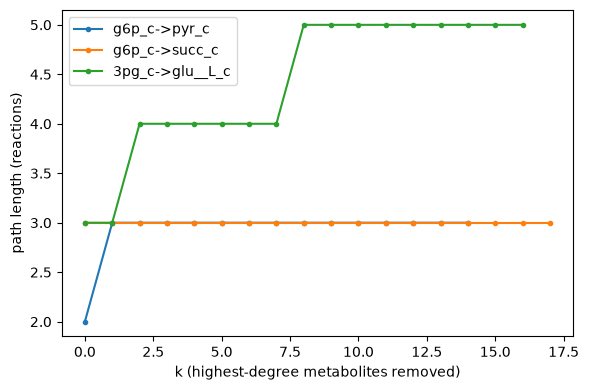

In [3]:
pairs = [("g6p_c", "pyr_c"), ("g6p_c", "succ_c"), ("3pg_c", "glu__L_c")]

def bfs_path(H, s, t):
    """Breadth-first search; neighbours visited in sorted order so ties are deterministic."""
    if s not in H or t not in H: return None
    prev = {s: None}; q = collections.deque([s])
    while q:
        u = q.popleft()
        if u == t: break
        for v in sorted(H.successors(u)):
            if v not in prev:
                prev[v] = u; q.append(v)
    if t not in prev: return None
    path, x = [], t
    while x is not None:
        path.append(x); x = prev[x]
    return path[::-1]

def plen(p): return None if p is None else len(p) - 1     # length = number of reactions (edges)

# --- GLCpts check ---
print("Cytoplasmic glucose in model:", [m.id for m in model.metabolites if m.id.startswith("glc__D")])
r = model.reactions.get_by_id("GLCpts")
print("GLCpts:", r.reaction, "| bounds", r.bounds)
p = bfs_path(G, "glc__D_e", "pyr_c")
print("glc__D_e -> pyr_c:", p, "length", plen(p))

# --- textbook glycolysis (G6P -> PYR), check each step is an edge of G ---
glycolysis = ["g6p_c", "f6p_c", "fdp_c", "g3p_c", "13dpg_c", "3pg_c", "2pg_c", "pep_c", "pyr_c"]
print("\nGlycolysis edges present in G:",
      all(G.has_edge(a, b) for a, b in zip(glycolysis, glycolysis[1:])), "| length", len(glycolysis) - 1)

# --- k = 0 results ---
print("\nk = 0")
k0_paths = {}
for s, t in pairs:
    p = bfs_path(G, s, t); k0_paths[(s, t)] = p
    n_sp = len(list(nx.all_shortest_paths(G, s, t)))
    print(f"  {s} -> {t}: length {plen(p)} ({n_sp} shortest path(s) exist)\n    {' -> '.join(p)}")

# --- removal of the k highest-degree metabolites ---
rank = sorted(G.nodes, key=lambda m: (-deg[m], m))      # degrees from the ORIGINAL graph; ties by id

def removal_set(k, s, t):
    return [m for m in rank if m not in (s, t)][:k]

def path_after_removal(s, t, k):
    rem = removal_set(k, s, t)
    H = G.copy(); H.remove_nodes_from(rem)
    return bfs_path(H, s, t), rem

K = [0, 2, 5, 10, 15]
rows = []
for s, t in pairs:
    for k in K:
        p, rem = path_after_removal(s, t, k)
        rows.append({"pair": f"{s}->{t}", "k": k, "length": plen(p),
                     "path": " -> ".join(p) if p else "DISCONNECTED",
                     "is_glycolysis": p == glycolysis if (s, t) == pairs[0] else None,
                     "removed": ", ".join(rem)})
res2 = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
display(res2[["pair", "k", "length", "is_glycolysis", "path"]])
print("Removed sets per pair:")
for s, t in pairs:
    print(f"{s} -> {t}")
    for k in K[1:]:
        print(f"  k={k}:", removal_set(k, s, t))

# --- first disconnection: remove one by one in degree order ---
print("\nFirst disconnection (one-at-a-time removal in degree order):")
for s, t in pairs:
    H = G.copy(); found = None
    for j, m in enumerate([m for m in rank if m not in (s, t)], 1):
        H.remove_node(m)
        if bfs_path(H, s, t) is None:
            found = (j, m); break
    print(f"  {s} -> {t}:", f"disconnected after removing #{found[0]} = {found[1]}" if found else "never disconnected")
    first_grid = next((r["k"] for r in rows if r["pair"] == f"{s}->{t}" and r["length"] is None), None)
    print(f"     first grid k with no path: {first_grid}")

# --- does the first path ever coincide with glycolysis? (fine scan k = 0..40) ---
s, t = pairs[0]
hit = None
for k in range(0, 41):
    p, _ = path_after_removal(s, t, k)
    if p == glycolysis:
        hit = k; break
print("\nFirst k (0..40) where g6p->pyr path equals glycolysis:", hit)

# --- plot length vs k ---
fig, ax = plt.subplots(figsize=(6, 4))
for s, t in pairs:
    ks = list(range(0, 31)); ls = []
    for k in ks:
        p, _ = path_after_removal(s, t, k); ls.append(np.nan if p is None else plen(p))
    ax.plot(ks, ls, marker="o", ms=3, label=f"{s}->{t}")
ax.set_xlabel("k (highest-degree metabolites removed)"); ax.set_ylabel("path length (reactions)")
ax.legend(); plt.tight_layout(); plt.show()

In [5]:
## 3. Two repairs. First, assign each edge a weight equal to the degree of its target metabolite,
## so that passing through a hub is expensive, and recompute the three paths with Dijkstra’s
## algorithm on the full graph (no removals). Second, instead of removing by degree, remove
## a list of metabolites chosen by a biochemist rather than by the graph: h c, h e, h2o c,
## pi c, atp c, adp c, amp c, nad c, nadh c, nadp c, nadph c, co2 c, coa c, nh4 c, o2 c,
## q8 c, q8h2 c; recompute the three paths with breadth-first search. Compare both with
## the results of item 2. Does either repair recover glycolysis? If one does and the other does
## not, say what the difference between them is, and whether a path that is only meaningful
## after a biochemist has told the algorithm what to ignore is still a result of the algorithm.

In [4]:
# --- Repair 1: weight = degree of target metabolite, Dijkstra, full graph ---
for u, v in G.edges:
    G[u][v]["w_deg"] = deg[v]

def path_cost(path, w="w_deg"):
    return sum(G[a][b][w] for a, b in zip(path, path[1:]))

rep1 = {}
print("Repair 1: Dijkstra with degree-of-target weights")
for s, t in pairs:
    p = nx.dijkstra_path(G, s, t, weight="w_deg")
    rep1[(s, t)] = p
    print(f"  {s} -> {t}: cost {path_cost(p)}, {plen(p)} reactions\n    {' -> '.join(p)}")
print("  Glycolysis cost under these weights:", path_cost(glycolysis),
      "| Dijkstra g6p->pyr cost:", path_cost(rep1[pairs[0]]))
print("  Recovers glycolysis?", rep1[pairs[0]] == glycolysis)

# --- Repair 2: remove biochemist's list, BFS ---
biochem = ["h_c", "h_e", "h2o_c", "pi_c", "atp_c", "adp_c", "amp_c", "nad_c", "nadh_c",
           "nadp_c", "nadph_c", "co2_c", "coa_c", "nh4_c", "o2_c", "q8_c", "q8h2_c"]
print("\nMissing from graph:", [m for m in biochem if m not in G])
H2 = G.copy(); H2.remove_nodes_from([m for m in biochem if m in H2])

rep2 = {}
print("Repair 2: BFS after removing currency metabolites")
for s, t in pairs:
    p = bfs_path(H2, s, t); rep2[(s, t)] = p
    print(f"  {s} -> {t}: length {plen(p)}\n    {' -> '.join(p) if p else 'DISCONNECTED'}")
print("  Recovers glycolysis?", rep2[pairs[0]] == glycolysis)
all_sp = list(nx.all_shortest_paths(H2, *pairs[0]))
print("  Glycolysis is among the shortest paths in H2:", glycolysis in all_sp, f"({len(all_sp)} shortest)")

# --- comparison table ---
rows = []
for pr in pairs:
    for name, d in [("item 2, k=0 (BFS)", k0_paths), ("repair 1 (Dijkstra)", rep1), ("repair 2 (BFS, curated)", rep2)]:
        p = d[pr]
        rows.append({"pair": f"{pr[0]}->{pr[1]}", "method": name, "length": plen(p),
                     "path": " -> ".join(p) if p else "DISCONNECTED"})
display(pd.DataFrame(rows))

Repair 1: Dijkstra with degree-of-target weights
  g6p_c -> pyr_c: cost 46, 3 reactions
    g6p_c -> 6pgl_c -> nadp_c -> pyr_c
  g6p_c -> succ_c: cost 42, 3 reactions
    g6p_c -> nadph_c -> icit_c -> succ_c
  3pg_c -> glu__L_c: cost 55, 4 reactions
    3pg_c -> 13dpg_c -> atp_c -> gln__L_c -> glu__L_c
  Glycolysis cost under these weights: 101 | Dijkstra g6p->pyr cost: 46
  Recovers glycolysis? False

Missing from graph: []
Repair 2: BFS after removing currency metabolites
  g6p_c -> pyr_c: length 7
    g6p_c -> f6p_c -> g3p_c -> 13dpg_c -> 3pg_c -> 2pg_c -> pep_c -> pyr_c
  g6p_c -> succ_c: length 10
    g6p_c -> f6p_c -> g3p_c -> 13dpg_c -> 3pg_c -> 2pg_c -> pep_c -> oaa_c -> mal__L_c -> fum_c -> succ_c
  3pg_c -> glu__L_c: length 8
    3pg_c -> 2pg_c -> pep_c -> oaa_c -> cit_c -> acon_C_c -> icit_c -> akg_c -> glu__L_c
  Recovers glycolysis? False
  Glycolysis is among the shortest paths in H2: False (1 shortest)


,pair,method,length,path
0,g6p_c->pyr_c,"item 2, k=0 (BFS)",2,g6p_c -> h_c -> pyr_c
1,g6p_c->pyr_c,repair 1 (Dijkstra),3,g6p_c -> 6pgl_c -> nadp_c -> pyr_c
2,g6p_c->pyr_c,"repair 2 (BFS, curated)",7,g6p_c -> f6p_c -> g3p_c -> 13dpg_c -> 3pg_c -> 2pg_c -> pep_c -> pyr_c
3,g6p_c->succ_c,"item 2, k=0 (BFS)",3,g6p_c -> f6p_c -> adp_c -> succ_c
4,g6p_c->succ_c,repair 1 (Dijkstra),3,g6p_c -> nadph_c -> icit_c -> succ_c
5,g6p_c->succ_c,"repair 2 (BFS, curated)",10,g6p_c -> f6p_c -> g3p_c -> 13dpg_c -> 3pg_c -> 2pg_c -> pep_c -> oaa_c -> mal__L_c -> fum_c -> succ_c
6,3pg_c->glu__L_c,"item 2, k=0 (BFS)",3,3pg_c -> 2pg_c -> h2o_c -> glu__L_c
7,3pg_c->glu__L_c,repair 1 (Dijkstra),4,3pg_c -> 13dpg_c -> atp_c -> gln__L_c -> glu__L_c
8,3pg_c->glu__L_c,"repair 2 (BFS, curated)",8,3pg_c -> 2pg_c -> pep_c -> oaa_c -> cit_c -> acon_C_c -> icit_c -> akg_c -> glu__L_c


In [7]:
## 4. Negative weights. Now assign each edge the net ATP consumption of its reaction:
## +1 per ATP consumed, −1 per ATP produced, 0 otherwise (read the stoichiometry of
## atp c in each reaction from the model). Lecture 6 states that Dijkstra’s algorithm is not
## valid when weights can be negative. Explain why, then run the Bellman–Ford algorithm
## instead for the same three pairs. Report whether the algorithm detects a negative-weight
## cycle reachable from glucose-6-phosphate. If it does, print the cycle and explain what a
## cycle with net ATP production means biologically, and what it reveals about representing
## reactions as edges between single metabolites.

In [6]:
# --- Why Dijkstra fails: tiny counterexample ---
toy = nx.DiGraph()
toy.add_weighted_edges_from([("A", "B", 2), ("A", "C", 3), ("C", "B", -2)])
print("True shortest A->B (Bellman-Ford):", nx.bellman_ford_path_length(toy, "A", "B"), "(A->C->B = 3-2 = 1)")
try:
    print("Dijkstra A->B:", nx.dijkstra_path_length(toy, "A", "B"))
except Exception as e:
    print("Dijkstra fails:", type(e).__name__, e)

# --- ATP-weighted graph ---
# Edge weight = net ATP consumption of the reaction: +coef consumed, -coef produced (reverse direction flips sign).
# If several reactions give the same edge (u,v) we keep the one with the minimum weight (and its reaction id).
atp = model.metabolites.get_by_id("atp_c")
Gw = nx.DiGraph(); Gw.add_nodes_from(G.nodes)

def add_w(u, v, w, rid):
    if u == v: return
    if not Gw.has_edge(u, v) or w < Gw[u][v]["w_atp"]:
        Gw.add_edge(u, v, w_atp=w, rxn=rid)

for r in used_rxns:
    c = r.metabolites.get(atp, 0)          # <0 if ATP is a substrate, >0 if a product
    w_fwd, w_rev = -c, +c
    subs  = [m.id for m, x in r.metabolites.items() if x < 0]
    prods = [m.id for m, x in r.metabolites.items() if x > 0]
    if r.upper_bound > 0:
        for s_ in subs:
            for p_ in prods: add_w(s_, p_, w_fwd, r.id)
    if r.lower_bound < 0:
        for s_ in subs:
            for p_ in prods: add_w(p_, s_, w_rev, r.id)

print("\nSame edge set as G:", set(Gw.edges) == set(G.edges))
print("Edges with negative weight:", sum(1 for *_, d in Gw.edges(data=True) if d["w_atp"] < 0))

# --- own Bellman-Ford with negative-cycle extraction ---
def bellman_ford(H, source, weight="w_atp"):
    INF = float("inf"); n = H.number_of_nodes()
    dist = {v: INF for v in H}; pred = {v: None for v in H}; dist[source] = 0
    for _ in range(n - 1):
        changed = False
        for u, v, d in H.edges(data=True):
            if dist[u] + d[weight] < dist[v]:
                dist[v] = dist[u] + d[weight]; pred[v] = u; changed = True
        if not changed: break
    for u, v, d in H.edges(data=True):          # n-th pass: any further relaxation => negative cycle
        if dist[u] != INF and dist[u] + d[weight] < dist[v]:
            pred[v] = u; x = v
            for _ in range(n): x = pred[x]      # walk back n steps to land inside the cycle
            cyc, y = [x], pred[x]
            while y != x:
                cyc.append(y); y = pred[y]
            cyc.append(x); cyc.reverse()
            return dist, pred, cyc
    return dist, pred, None

def show_cycle(cyc):
    tot = 0
    for a, b in zip(cyc, cyc[1:]):
        d = Gw[a][b]; tot += d["w_atp"]
        print(f"   {a} --[{d['rxn']}, w={d['w_atp']:+}]--> {b}")
    print("   total cycle weight:", tot)

# --- run for the three pairs ---
for s, t in pairs:
    print(f"\n=== {s} -> {t} ===")
    dist, pred, cyc = bellman_ford(Gw, s)
    reach = nx.descendants(Gw, s) | {s}
    print("Negative cycle reachable from source (own BF):", cyc is not None)
    print("networkx check on reachable subgraph:",
          nx.negative_edge_cycle(Gw.subgraph(reach).copy(), weight="w_atp"))   # .copy() fixes the frozen-graph error
    if cyc:
        print("Cycle found:", " -> ".join(cyc)); show_cycle(cyc)
        cyc_nodes = set(cyc)
        reachable_from_cycle = set().union(*(nx.descendants(Gw, c) for c in cyc_nodes)) | cyc_nodes
        print(f"Target reachable from the cycle (=> distance is -infinity): {t in reachable_from_cycle}")
    try:
        p = nx.bellman_ford_path(Gw, s, t, weight="w_atp")
        print("nx.bellman_ford_path:", p, "net ATP", nx.bellman_ford_path_length(Gw, s, t, weight="w_atp"))
    except nx.NetworkXUnbounded as e:
        print("nx.bellman_ford_path raised NetworkXUnbounded:", e)

True shortest A->B (Bellman-Ford): 1 (A->C->B = 3-2 = 1)
Dijkstra A->B: 2

Same edge set as G: True
Edges with negative weight: 28

=== g6p_c -> pyr_c ===
Negative cycle reachable from source (own BF): True
networkx check on reachable subgraph: True
Cycle found: h_c -> pyr_c -> h_e -> h_c
   h_c --[PYK, w=-1.0]--> pyr_c
   pyr_c --[PYRt2, w=+0]--> h_e
   h_e --[ATPS4r, w=-1.0]--> h_c
   total cycle weight: -2.0
Target reachable from the cycle (=> distance is -infinity): True
nx.bellman_ford_path raised NetworkXUnbounded: Negative cycle detected.

=== g6p_c -> succ_c ===
Negative cycle reachable from source (own BF): True
networkx check on reachable subgraph: True
Cycle found: h_c -> pyr_c -> h_e -> h_c
   h_c --[PYK, w=-1.0]--> pyr_c
   pyr_c --[PYRt2, w=+0]--> h_e
   h_e --[ATPS4r, w=-1.0]--> h_c
   total cycle weight: -2.0
Target reachable from the cycle (=> distance is -infinity): True
nx.bellman_ford_path raised NetworkXUnbounded: Negative cycle detected.

=== 3pg_c -> glu__L_c ===